# № 8. EDA корпуса: 845-П и все источники

№ 10 готовит данные; этот ноутбук показывает состав, частоты, размеры, длины, аномалии и ссылки. Команды запуска и схема JSONL — в `LIGHT.md`.

Вход — ODT из снимка `dev` `bd7d25c`: один выбранный формат для каждого документа. Отдельно учитываем идентичный экспорт, регистрационную карточку и навигационную страницу. Все файловые цели прямых гиперссылок 845-П уже представлены среди исходников. Рекурсивное расширение корпуса не выполняется.

**Единица** — исходный пункт, статья, заголовок, сноска или редакторская вставка. **Чанк** — индексируемый фрагмент единицы. Это разные уровни: заголовки и вставки сохраняются для проверки источника, но самостоятельных чанков не создают.

In [1]:
import json
from pathlib import Path
from collections import Counter
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA = ROOT / "data/eda"
CORPUS = ROOT / "data/processed/corpus"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

def load(scope):
    names = ["documents", "unit_lengths", "chunk_lengths", "words", "acts", "link_statuses", "anomalies"]
    return {n: pd.read_csv(DATA / scope / f"{n}.csv") for n in names}

def bars(frame, ax, title, key="term", n=12):
    frame.head(n).iloc[::-1].plot.barh(x=key, y="count", ax=ax, legend=False, color="#307e99")
    ax.set(title=title, xlabel="Число вхождений", ylabel="")

main, all_data = load("main"), load("all")
summary = {s: json.loads((DATA / s / "summary.json").read_text()) for s in ["main", "all"]}
display(pd.DataFrame(summary).drop(index="legal_status").rename(columns={"main": "845-П", "all": "Весь корпус"}))

,845-П,Весь корпус
documents,1,90
acts,1,88
units,369,24962
chunks,411,20405
max_tokens,507,508
word_occurrences,42994,1889816
word_forms,4819,26692
hyperlinks,845,67259
links_resolved_to_unit,763,42098
links_resolved_to_chunks,653,38576


## 1. Основной документ: структура и длины

Токены исходной единицы — BGE-M3 с техническими токенами, без добавленного контекста. Токены чанка — **весь `embedding_text`**, включая название, адрес пункта, контекст и технические токены. Верхний предел 512 проверяется после разбиения. Короткий контекст ограничен 96 токенами; полные названия остаются в метаданных.

Перечни `1)`, `2)` сохраняются внутри пункта. Заголовки передаются через контекст. Числа, индексы и ссылки не вычищаются как «шум».

,chars,words,tokens
count,329.0,329.0,329.0
mean,1123.0,128.4,249.4
std,1570.8,179.9,345.2
min,57.0,7.0,17.0
50%,691.0,74.0,157.0
95%,3253.8,365.6,700.4
99%,6070.3,714.1,1290.1
max,17385.0,1968.0,3849.0


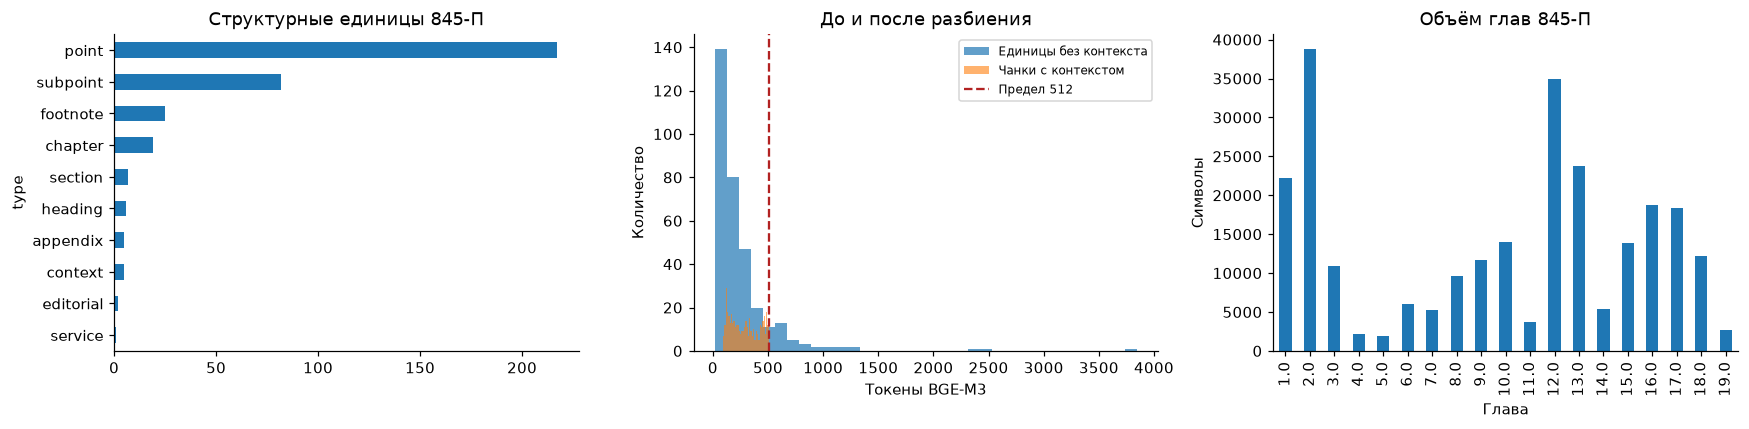

**Наблюдение:** 38 индексируемых единиц длиннее 512 токенов даже без контекста. Получено 411 чанков; максимум полного входа — 507. Поэтому единицу сохраняем целиком, а для поиска используем её короткие фрагменты.

In [2]:
u, c = main["unit_lengths"], main["chunk_lengths"]
indexable = u[u.indexable]
display(indexable[["chars", "words", "tokens"]].describe(percentiles=[.5, .95, .99]).round(1))
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
u.type.value_counts().sort_values().plot.barh(ax=axes[0], title="Структурные единицы 845-П")
axes[1].hist(indexable.tokens, bins=35, alpha=.7, label="Единицы без контекста")
axes[1].hist(c.tokens, bins=35, alpha=.6, label="Чанки с контекстом")
axes[1].axvline(512, color="firebrick", ls="--", label="Предел 512")
axes[1].set(xlabel="Токены BGE-M3", ylabel="Количество", title="До и после разбиения")
axes[1].legend(fontsize=8)
u[u.appendix.isna()].groupby("chapter").chars.sum().plot.bar(ax=axes[2], title="Объём глав 845-П")
axes[2].set(xlabel="Глава", ylabel="Символы")
plt.tight_layout(); plt.show()
display(Markdown(f"**Наблюдение:** {int((indexable.tokens > 512).sum())} индексируемых единиц длиннее 512 токенов даже без контекста. Получено {len(c)} чанков; максимум полного входа — {int(c.tokens.max())}. Поэтому единицу сохраняем целиком, а для поиска используем её короткие фрагменты."))

## 2. Основной документ: частоты и ссылки

Слова — последовательности букв в нижнем регистре, без лемматизации и удаления стоп-слов; маркеры изображений исключены. Частоты описывают весь предварительный текст, включая сноски и редакторские вставки. Номера актов ищутся после `N`/`№`; упоминание не равно гиперссылке и само по себе не идентифицирует дату и редакцию акта.

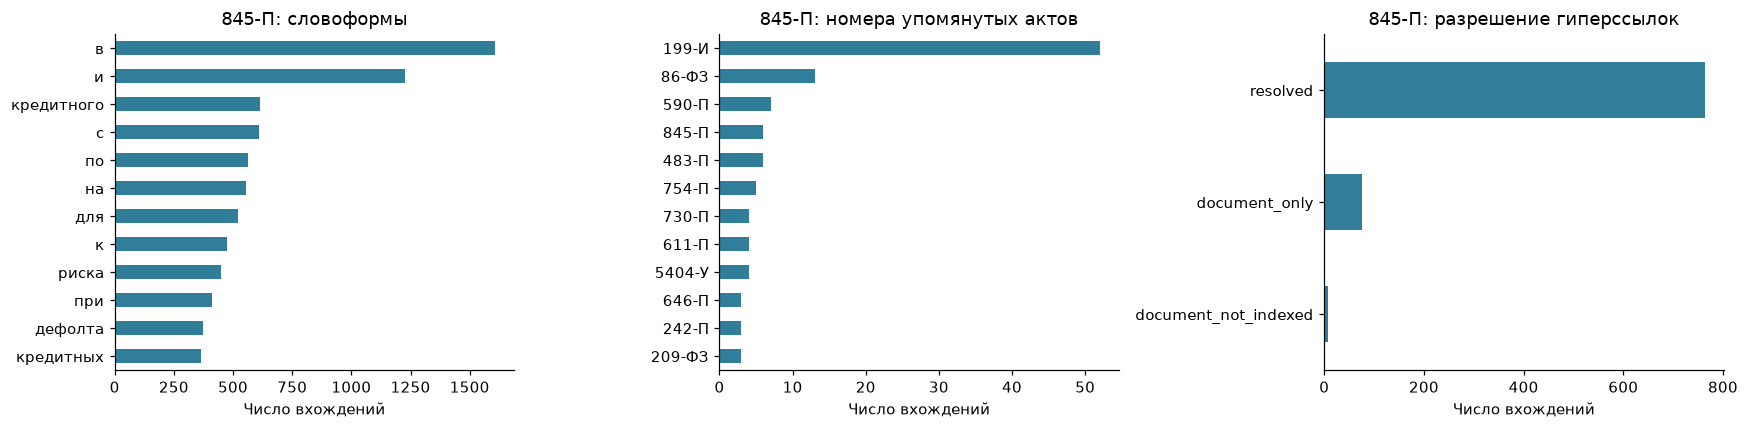

,term,count
0,199-И,52
1,86-ФЗ,13
2,590-П,7
3,845-П,6
4,483-П,6
5,754-П,5
6,730-П,4
7,611-П,4
8,5404-У,4
9,646-П,3


Из 845 гиперссылок 763 ведут к конкретной структурной единице, а 653 — к её индексируемым фрагментам. Ссылка на заголовок может разрешиться в единицу без собственного чанка: текст раздела получают через дочерние `parent_id`.

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
bars(main["words"], axes[0], "845-П: словоформы")
bars(main["acts"], axes[1], "845-П: номера упомянутых актов")
bars(main["link_statuses"].sort_values("count", ascending=False), axes[2], "845-П: разрешение гиперссылок", key="status")
plt.tight_layout(); plt.show()
display(main["acts"].head(10))
display(Markdown(f"Из {summary['main']['hyperlinks']} гиперссылок {summary['main']['links_resolved_to_unit']} ведут к конкретной структурной единице, а {summary['main']['links_resolved_to_chunks']} — к её индексируемым фрагментам. Ссылка на заголовок может разрешиться в единицу без собственного чанка: текст раздела получают через дочерние `parent_id`."))

## 3. Все источники: состав и неоднородность

Одни и те же PDF/RTF/ODT не считаются разными актами: здесь парсится только ODT. Документ определяется издателем, видом, датой и номером, а точная копия — хешем нормализованного текста. Если одному акту соответствуют разные тексты, код исключает конфликт из индекса до выбора редакции. Совпадение номера без остальных реквизитов не считается дублем.

,file_id,number,role,canonical_file_id,edition_conflict
3,107917,NaN,navigation,107917,False
46,411309161,845-П,act,845_p,False
47,411309162,845-П,registration_card,411309162,False


,number,words,bytes
25,6406-У,457750,1476890
9,127-ФЗ,293876,682365
22,809-П,128281,360957
42,6800-У,88530,278289
79,199-И,78775,336245
1,395-I,61676,147724
49,3624-У,58793,134806
4,86-ФЗ,57751,144373
6,135-ФЗ,56750,140436
65,4838-У,46233,95818


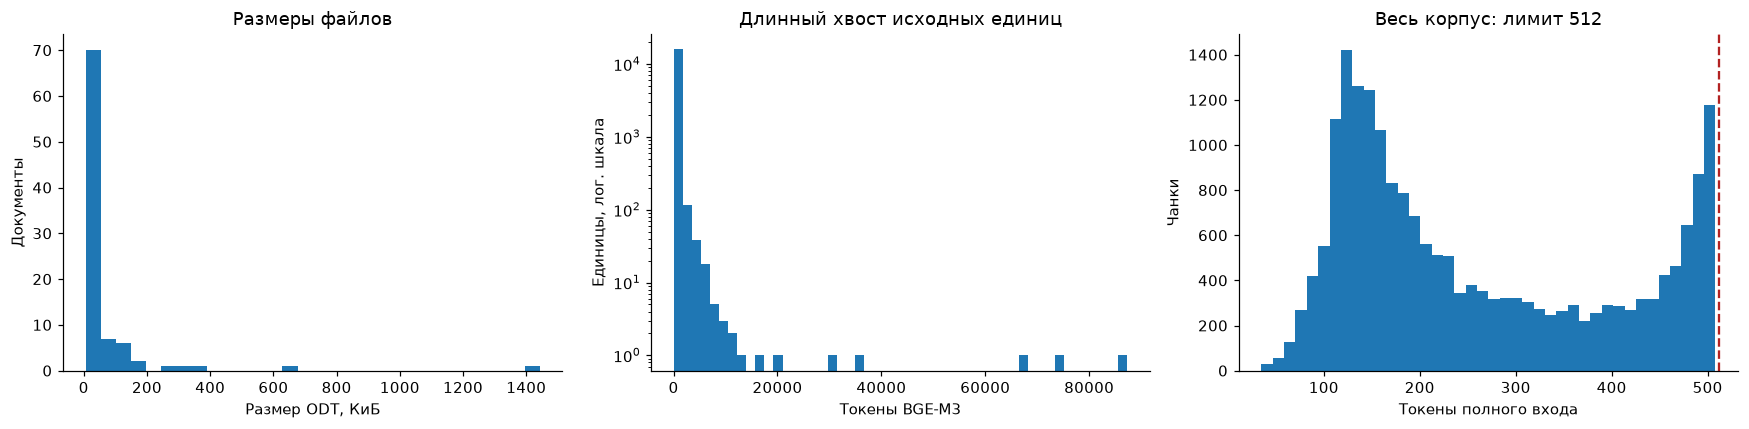

Крупнейший источник содержит 24.2% всех вхождений слов. Общие частоты зависят от объёма документов, поэтому выводы по 845-П рассматриваем отдельно.

In [4]:
registry = pd.read_csv(DATA / "documents.csv")
d = all_data["documents"]
au = all_data["unit_lengths"]
ac = all_data["chunk_lengths"]
display(registry[~registry.selected][["file_id", "number", "role", "canonical_file_id", "edition_conflict"]])
display(d[["number", "words", "bytes"]].nlargest(10, "words"))
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
axes[0].hist(d.bytes / 1024, bins=30)
axes[0].set(xlabel="Размер ODT, КиБ", ylabel="Документы", title="Размеры файлов")
axes[1].hist(au.loc[au.indexable, "tokens"], bins=50, log=True)
axes[1].set(xlabel="Токены BGE-M3", ylabel="Единицы, лог. шкала", title="Длинный хвост исходных единиц")
axes[2].hist(ac.tokens, bins=40)
axes[2].axvline(512, color="firebrick", ls="--")
axes[2].set(xlabel="Токены полного входа", ylabel="Чанки", title="Весь корпус: лимит 512")
plt.tight_layout(); plt.show()
assert ac.tokens.max() <= 512
assert d.document_id.is_unique
display(Markdown(f"Крупнейший источник содержит {d.words.max() / d.words.sum():.1%} всех вхождений слов. Общие частоты зависят от объёма документов, поэтому выводы по 845-П рассматриваем отдельно."))

## 4. Все источники: упоминания, юридический статус и аномалии

Статус всего документа хранится с датой проверки, URL и основанием в `data/legal_status.csv`. `repealed` — подтверждена полная отмена; `active` предусмотрен для явно подтверждённого действующего акта; `unknown` — вывод не подтверждён; `not_applicable` — справочный материал. Дата проверки статуса **не является датой редакции** локального ODT. Отменённые акты сохранены для исторических ссылок.

Основания ручных отметок: пункт 11.3 [220-И](https://www.cbr.ru/Queries/XsltBlock/File/170786/-1/2563#page=53), пункт 8.2 [878-П](https://www.cbr.ru/Queries/XsltBlock/File/87500/-1/2605#page=24), пункт 19.2 [845-П](https://base.garant.ru/411309161/95ef042b11da42ac166eeedeb998f688/). Частичная отмена 5404-У и других актов не была записана как полная.

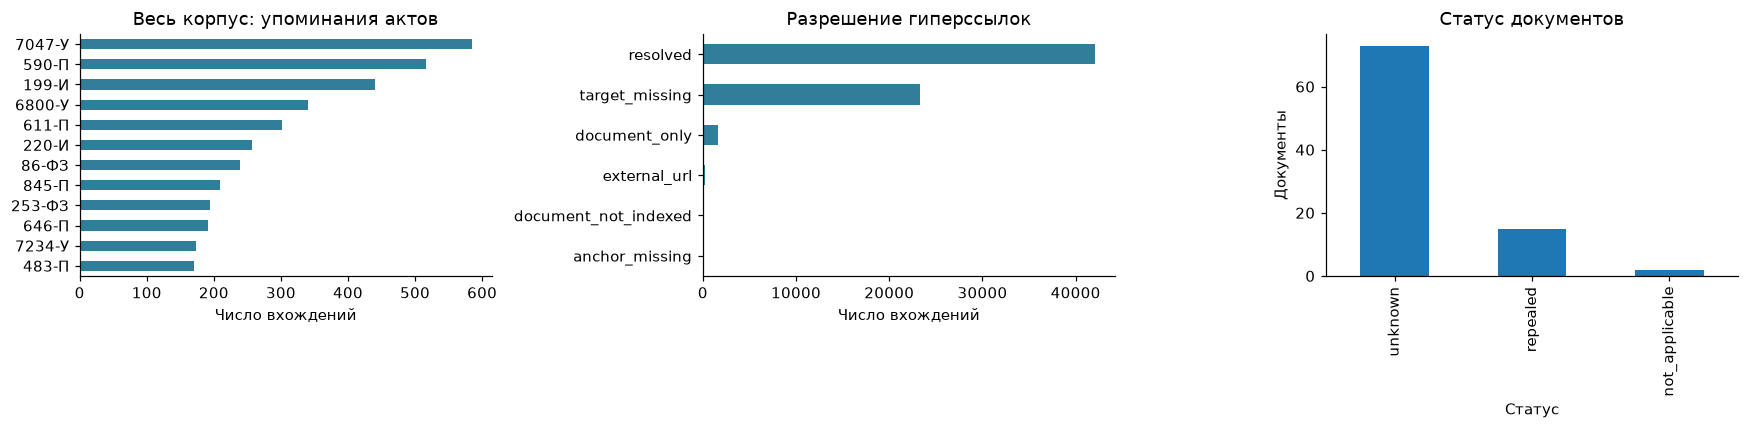

,Случаи
issue,
target_missing,23258
repeated_number,3773
status_unknown,76
document_not_indexed,14
excluded_role,2
anchor_missing,2
duplicate,1


,number,legal_status.checked_on,legal_status.source_url
17,5886-У,2026-11-08,https://www.cbr.ru/Queries/XsltBlock/File/1707...
28,6393-У,2026-11-08,https://www.cbr.ru/Queries/XsltBlock/File/1707...
29,6436-У,2026-11-08,https://www.cbr.ru/Queries/XsltBlock/File/1707...
33,6465-У,2026-11-08,https://www.cbr.ru/Queries/XsltBlock/File/8750...
52,483-П,2026-11-08,https://base.garant.ru/411309161/95ef042b11da4...
54,3869-У,2026-11-08,https://base.garant.ru/411309161/95ef042b11da4...
63,611-П,2026-11-08,https://www.cbr.ru/Queries/XsltBlock/File/8750...
70,4988-У,2026-11-08,https://www.cbr.ru/Queries/XsltBlock/File/8750...
74,5091-У,2026-11-08,https://base.garant.ru/411309161/95ef042b11da4...
76,5212-У,2026-11-08,https://www.cbr.ru/Queries/XsltBlock/File/8750...


In [5]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
bars(all_data["acts"], axes[0], "Весь корпус: упоминания актов")
bars(all_data["link_statuses"].sort_values("count", ascending=False), axes[1], "Разрешение гиперссылок", key="status")
d["legal_status.status"].value_counts().plot.bar(ax=axes[2], title="Статус документов")
axes[2].set(xlabel="Статус", ylabel="Документы")
plt.tight_layout(); plt.show()
display(all_data["anomalies"].issue.value_counts().rename("Случаи").to_frame())
display(d[d["legal_status.status"] == "repealed"][["number", "legal_status.checked_on", "legal_status.source_url"]])

`target_missing` означает отсутствие цели в нашей выборке, а не битую ссылку в интернете. `anchor_missing` — документ есть, но нужная закладка не найдена; `ambiguous_anchor` — совпало несколько единиц; `document_only` — адресован акт целиком; `document_not_indexed` — найден служебный источник. Неоднозначные ссылки не подменяются догадками.

`repeated_number` — повтор номера внутри области документа, например в отдельных формах отчётности или сносках. Записи не удаляются: ID получает суффикс `occurrence`, а исходный блок и anchor позволяют различать их. Это сигнал проверки структуры, а не доказательство дублирования НПА.

## 5. Как пройти по ссылке к тексту

Закладка уникальна только **внутри документа**. Пара `(target_document_id, target_anchor)` разрешается в `target_unit_id` и диапазон `target_span`. Затем `target_chunk_ids` дают пересекающиеся фрагменты. При ссылке на заголовок читают саму единицу и её дочерние единицы; в индекс заголовок отдельно не отправляется.

Ниже — реальный переход из 845-П в другой документ. Числовой суффикс URL ГАРАНТ сопоставляется с закладкой `anchor…` из ODT; закладки не генерируются из номера пункта.

In [6]:
def rows(name):
    with (CORPUS / f"{name}.jsonl").open() as f:
        yield from (json.loads(line) for line in f)

main_id = main["documents"].document_id.iloc[0]
link = next(l for l in rows("links") if l["source_document_id"] == main_id
            and l["target_document_id"] != main_id and l["target_chunk_ids"])
unit = next(u for u in rows("units") if u["id"] == link["target_unit_id"])
fragment = next(c for c in rows("chunks") if c["id"] == link["target_chunk_ids"][0])
display(pd.Series({k: link[k] for k in ["url", "target_document_id", "target_anchor", "target_unit_id", "target_chunk_ids"]}))
a, b = link["target_span"]
print("Текст блока, к которому прикреплён anchor:", unit["text"][a:b][:900])
print("Чанк:", fragment["id"], "| токенов:", fragment["tokens"])
assert fragment["text"] == unit["text"][fragment["start"]:fragment["end"]]

url                   http://ivo.garant.ru/document/redirect/1212740...
target_document_id    Российская Федерация|Федеральный закон|2002-07...
target_anchor                                                anchor7204
target_unit_id                                 12127405:main:article-72
target_chunk_ids                     [12127405:main:article-72#chunk-1]
dtype: object

Текст блока, к которому прикреплён anchor: В целях определения размера и достаточности собственных средств (капитала) кредитной организации (банковской группы) Банк России проводит оценку ее активов и пассивов, достаточности резервов, создаваемых под риски, величины кредитного риска, учитываемой при расчете нормативов достаточности собственных средств (капитала) и иных обязательных нормативов кредитной организации (банковской группы), на основании методик оценки, устанавливаемых нормативными актами Банка России. Кредитная организация (банковская группа) отражает в своей бухгалтерской (финансовой) и иной отчетности размер собственных средств (капитала) и величину кредитного риска, учитываемую при расчете нормативов достаточности собственных средств (капитала) и иных обязательных нормативов, определенные Банком России.
Чанк: 12127405:main:article-72#chunk-1 | токенов: 455


## Практические выводы

- **Состав:** сохраняем имеющиеся уникальные тексты и прямые цели 845-П; лидеры частот всего корпуса не становятся автоматическим списком новых загрузок.
- **Поиск:** индексируем `embedding_text`, после извлечения возвращаем `unit_id` и исходный пункт. Предел 512 относится к этому сохранённому входу, а не к произвольно добавленному позднее контексту.
- **Ссылки:** различаем ссылку на акт, конкретную закладку и текстовое упоминание. Не найденные цели остаются видимыми в EDA.
- **Качество:** повтор номера не удаляет текст; разные форматы не увеличивают число актов. Заголовки и редакторские вставки сохраняются для аудита, но не образуют чанки.
- **Ограничения:** статус большинства актов пока не подтверждён; актуальность редакций не установлена. Формулы-изображения сохранены как файлы и маркеры, без OCR. Разбиение очень длинной таблицы может пройти внутри строки; полная таблица остаётся в единице. Эта EDA не оценивает качество поиска и не заменяет юридическую проверку редакций.